In [1]:
#import different libraries:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


In [2]:
import os
data_path = 'my_energy_data.csv' if os.path.exists('my_energy_data.csv') else 'weather_daily_darksky.csv'
energy = pd.read_csv(data_path)
energy


,energy_median,energy_mean,energy_max,energy_count,energy_std,energy_sum,energy_min,temperatureMax,windBearing,dewPoint,...,cloudy,fog,partly-cloudy-day,partly-cloudy-night,wind,rain,snow,year,month,date
0,0.1150,0.300233,1.179,30,0.361231,9.007,0.047,6.91,245,2.15,...,False,False,True,False,False,True,False,2011,12,3
1,0.1750,0.432563,1.914,48,0.484152,20.763,0.026,9.02,263,1.79,...,False,False,False,False,True,True,False,2011,12,4
2,0.0780,0.125417,0.934,48,0.153327,6.020,0.025,10.69,103,8.23,...,False,True,False,False,False,True,False,2011,12,5
3,0.1140,0.277542,1.216,48,0.313399,13.322,0.027,12.89,234,5.96,...,False,False,False,False,True,True,False,2011,12,6
4,0.1035,0.188792,0.873,48,0.209613,9.062,0.026,11.85,1,7.48,...,False,False,True,False,False,True,False,2011,12,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57300,0.1190,0.119000,0.119,1,0.189224,0.119,0.119,8.88,172,2.69,...,False,False,False,False,True,True,False,2014,2,28
57301,0.3210,0.321000,0.321,1,0.350170,0.321,0.321,8.88,172,2.69,...,False,False,False,False,True,True,False,2014,2,28
57302,0.1070,0.107000,0.107,1,0.222648,0.107,0.107,8.88,172,2.69,...,False,False,False,False,True,True,False,2014,2,28
57303,0.0530,0.053000,0.053,1,0.228425,0.053,0.053,8.88,172,2.69,...,False,False,False,False,True,True,False,2014,2,28


In [3]:
energy_data = energy.drop(columns = ['Unnamed: 0', 'Unnamed: 0.1', 'energy_median','energy_mean','energy_max','energy_count','energy_std', 'energy_min'], errors='ignore')
energy_data


,energy_sum,temperatureMax,windBearing,dewPoint,cloudCover,windSpeed,pressure,apparentTemperatureHigh,visibility,humidity,...,cloudy,fog,partly-cloudy-day,partly-cloudy-night,wind,rain,snow,year,month,date
0,9.007,6.91,245,2.15,0.34,4.79,1007.32,3.77,13.15,0.83,...,False,False,True,False,False,True,False,2011,12,3
1,20.763,9.02,263,1.79,0.29,7.06,1008.76,4.98,13.12,0.68,...,False,False,False,False,True,True,False,2011,12,4
2,6.020,10.69,103,8.23,0.70,2.62,1015.07,10.69,2.82,0.95,...,False,True,False,False,False,True,False,2011,12,5
3,13.322,12.89,234,5.96,0.53,7.01,1010.84,12.89,12.59,0.81,...,False,False,False,False,True,True,False,2011,12,6
4,9.062,11.85,1,7.48,0.77,4.77,1021.96,11.85,11.76,0.81,...,False,False,True,False,False,True,False,2011,12,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57300,0.119,8.88,172,2.69,0.42,5.30,996.87,5.63,12.05,0.75,...,False,False,False,False,True,True,False,2014,2,28
57301,0.321,8.88,172,2.69,0.42,5.30,996.87,5.63,12.05,0.75,...,False,False,False,False,True,True,False,2014,2,28
57302,0.107,8.88,172,2.69,0.42,5.30,996.87,5.63,12.05,0.75,...,False,False,False,False,True,True,False,2014,2,28
57303,0.053,8.88,172,2.69,0.42,5.30,996.87,5.63,12.05,0.75,...,False,False,False,False,True,True,False,2014,2,28


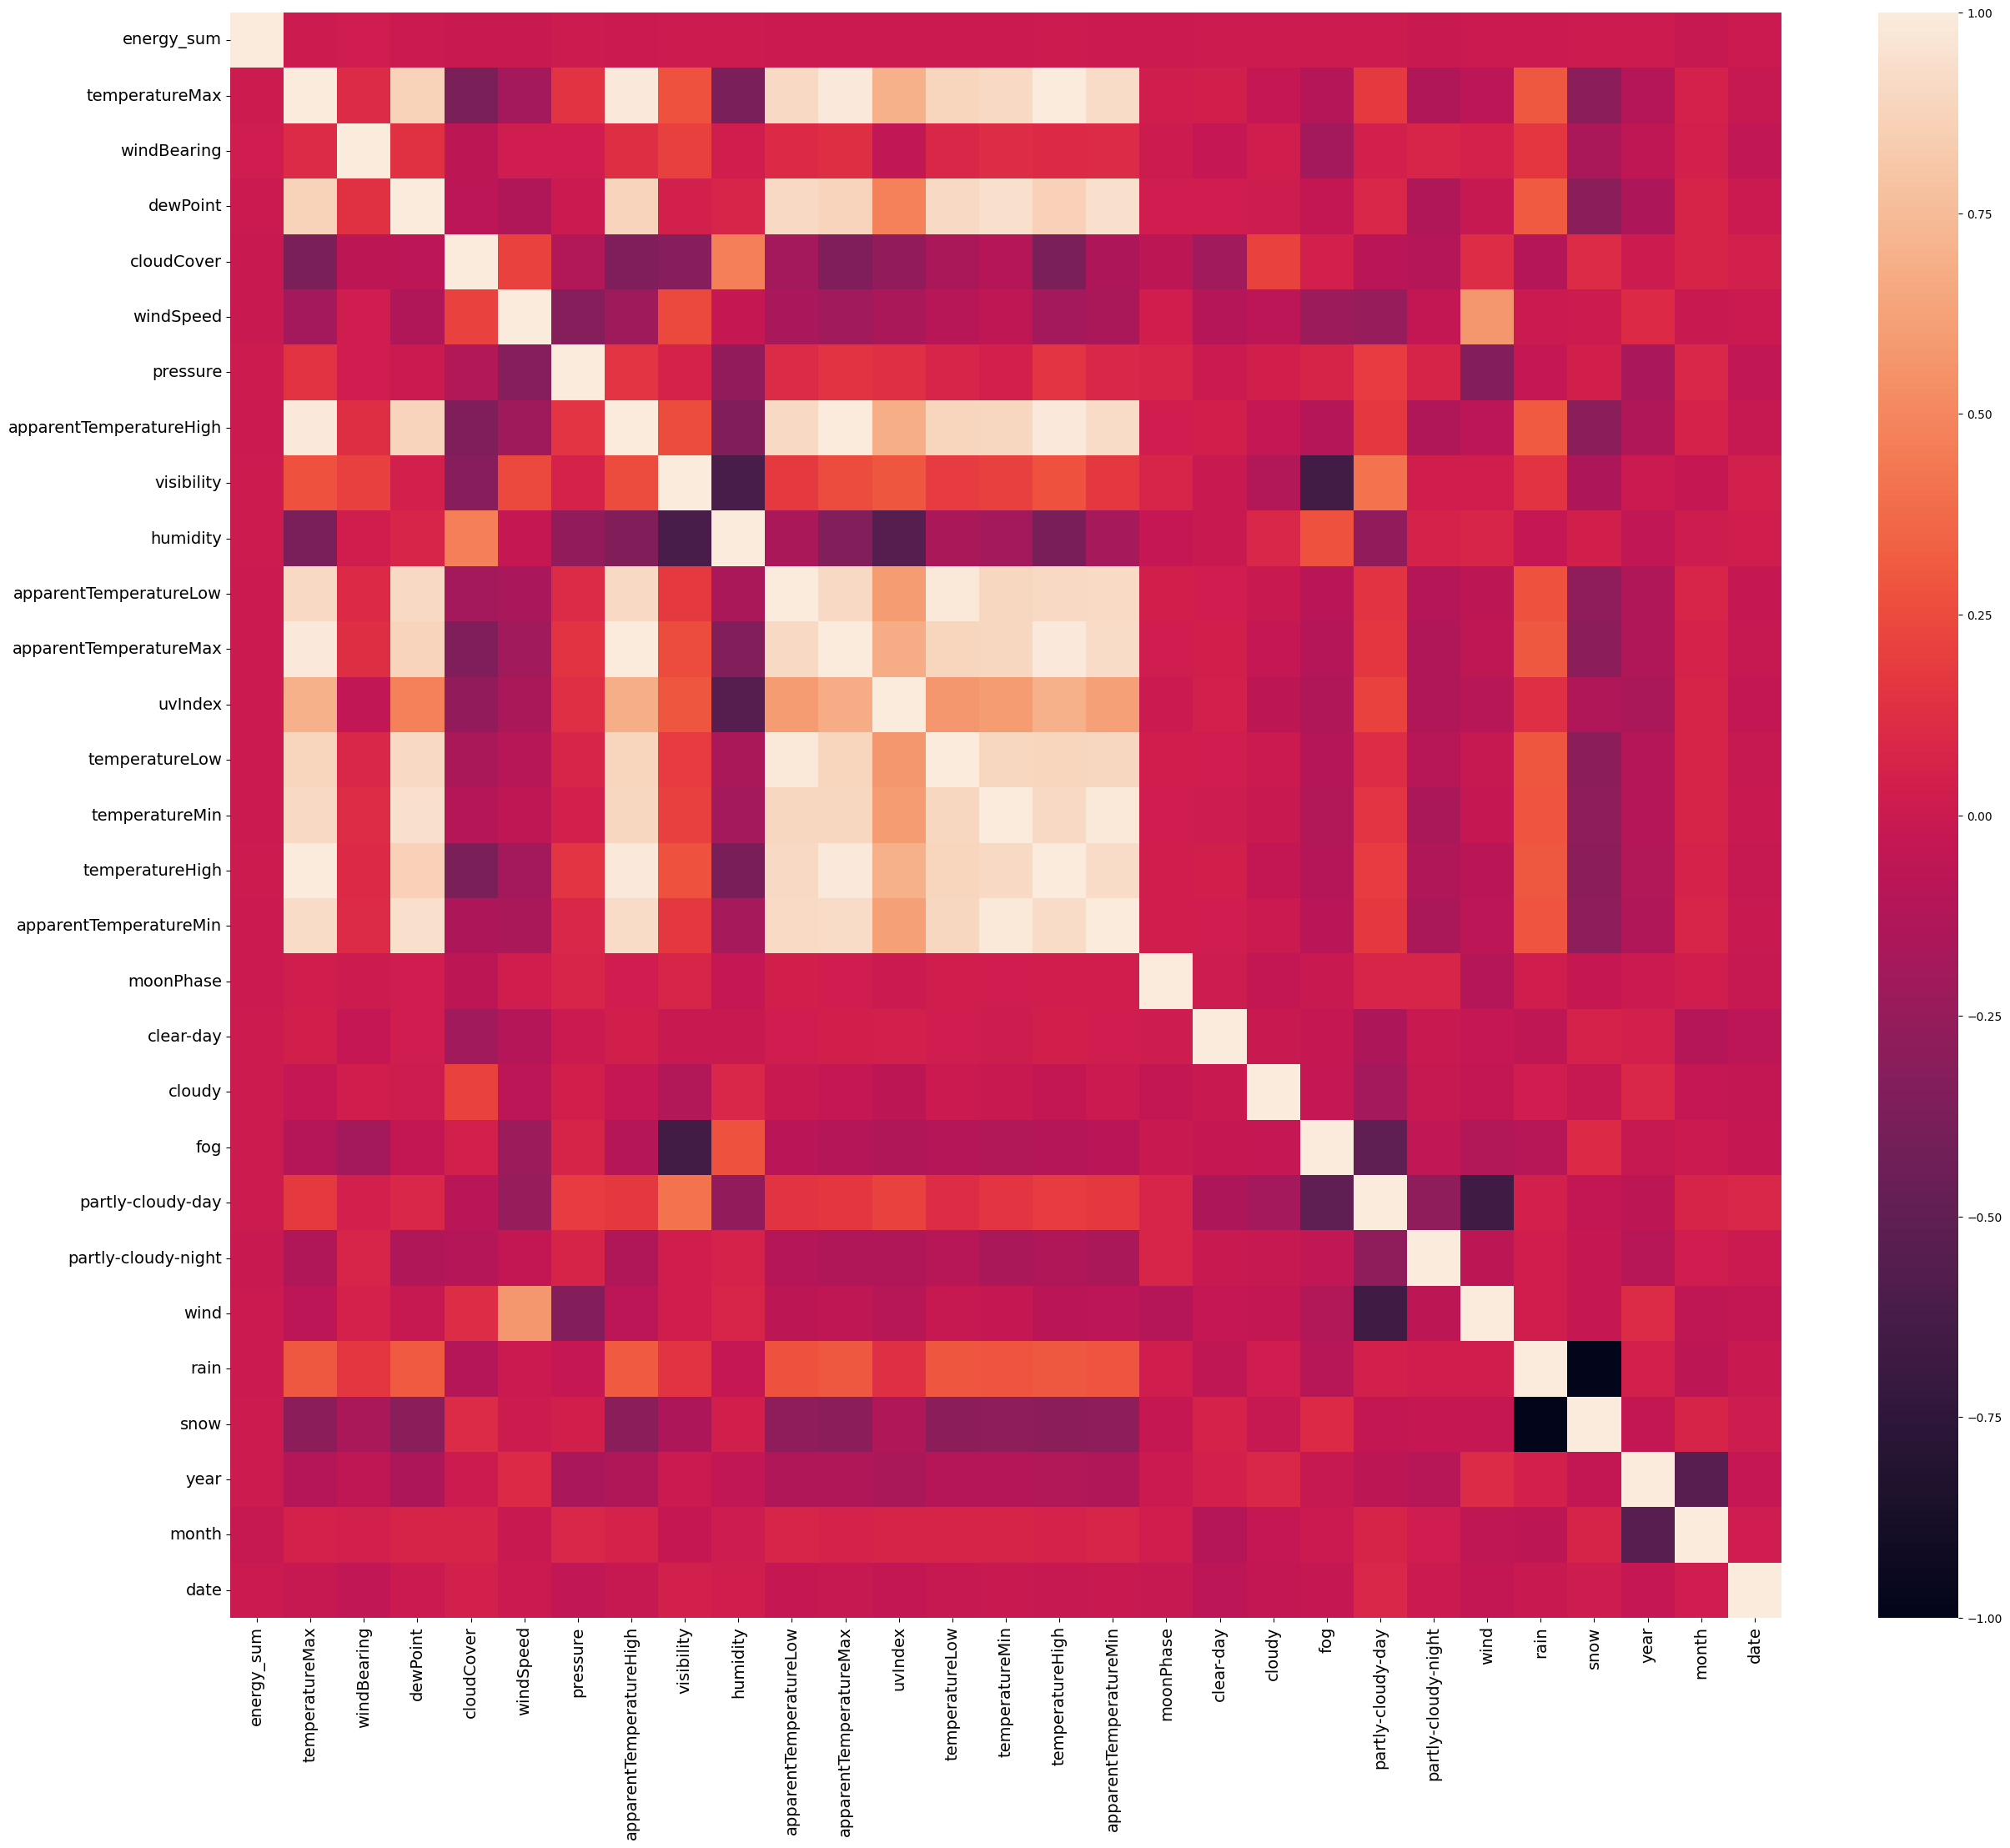

In [4]:
#now first of all find out co-relation with help of Seaborn's heatmap:
plt.figure(figsize = (30,25))
sns.heatmap(energy_data.corr(numeric_only=True))
plt.xticks(fontsize = 14)
plt.yticks(fontsize = 14)
plt.show()


In [5]:
#Now we can choose different columns according to strong or weak relation between our depemdent and independent columns;


In [6]:
# 1) dewpoint, 2) apparentTemperatureHigh, 3) apparentTemperatureLow, 4) apparentTemperatureMax, 5) uvindex
# 6) temperatureLow, 7) temperatureMin, 8) temperatureHigh, 9)apparentTemperatureMin


In [7]:
#To remove unnecessary columns;
final = energy_data.drop(columns = ['temperatureMax', 'windBearing', 'cloudCover', 'windSpeed', 'pressure', 'visibility', 'humidity', 'moonPhase', 'clear-day', 'cloudy','fog','partly-cloudy-day','partly-cloudy-night','wind','rain', 'snow'], errors='ignore')
final


,energy_sum,dewPoint,apparentTemperatureHigh,apparentTemperatureLow,apparentTemperatureMax,uvIndex,temperatureLow,temperatureMin,temperatureHigh,apparentTemperatureMin,year,month,date
0,9.007,2.15,3.77,1.90,3.77,1.0,5.16,2.68,6.91,-1.61,2011,12,3
1,20.763,1.79,4.98,0.63,5.14,1.0,4.27,4.91,9.02,0.94,2011,12,4
2,6.020,8.23,10.69,7.99,10.69,1.0,9.39,7.10,10.69,5.95,2011,12,5
3,13.322,5.96,12.89,-0.37,12.89,1.0,3.76,4.27,12.89,0.63,2011,12,6
4,9.062,7.48,11.85,10.17,11.85,1.0,10.17,9.46,11.85,7.03,2011,12,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...
57300,0.119,2.69,5.63,1.03,5.63,1.0,5.54,4.22,8.88,1.12,2014,2,28
57301,0.321,2.69,5.63,1.03,5.63,1.0,5.54,4.22,8.88,1.12,2014,2,28
57302,0.107,2.69,5.63,1.03,5.63,1.0,5.54,4.22,8.88,1.12,2014,2,28
57303,0.053,2.69,5.63,1.03,5.63,1.0,5.54,4.22,8.88,1.12,2014,2,28


In [8]:
#Setting the value for X and Y
x = final.drop('energy_sum', axis = 'columns', errors='ignore')
y = final['energy_sum']


In [9]:
#Splitting the dataset
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 100)


In [10]:
#Fitting the Multiple Linear Regression model
from sklearn.linear_model import LinearRegression
mlr = LinearRegression()
mlr.fit(x_train, y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [11]:
print("Intercept: ", mlr.intercept_)
print("Coefficients:")
list(zip(x.columns, mlr.coef_))


Intercept:  1098.6658152598009
Coefficients:


[('dewPoint', np.float64(0.28349103383285623)),
 ('apparentTemperatureHigh', np.float64(-0.08998951803483844)),
 ('apparentTemperatureLow', np.float64(-0.11371684970346536)),
 ('apparentTemperatureMax', np.float64(-0.07772544092465135)),
 ('uvIndex', np.float64(0.060792469142463286)),
 ('temperatureLow', np.float64(0.10414223224147852)),
 ('temperatureMin', np.float64(-0.26100421183752115)),
 ('temperatureHigh', np.float64(0.29047417769164896)),
 ('apparentTemperatureMin', np.float64(-0.11766475672999861)),
 ('year', np.float64(-0.536038527686033)),
 ('month', np.float64(-0.14696113419504236)),
 ('date', np.float64(-0.003384704916919358))]

In [12]:
#Prediction of test set
y_pred_mlr= mlr.predict(x_test)
#Predicted values
print("Prediction for test set: {}".format(y_pred_mlr))


Prediction for test set: [20.04496366 21.47998137 20.65394004 ... 20.14777337 19.99847778
 19.85963603]


In [13]:
#Actual value and the predicted value
mlr_diff = pd.DataFrame({'Actual value': y_test, 'Predicted value': y_pred_mlr})
mlr_diff.head()


,Actual value,Predicted value
4781,17.247,20.044964
2640,12.596,21.479981
18713,39.394,20.653940
47204,19.521,19.086327
25539,6.577,21.459736


In [14]:
#Model Evaluation
from sklearn import metrics
meanAbErr = metrics.mean_absolute_error(y_test, y_pred_mlr)
meanSqErr = metrics.mean_squared_error(y_test, y_pred_mlr)
rootMeanSqErr = np.sqrt(metrics.mean_squared_error(y_test, y_pred_mlr))
print('R squared: {:.2f}'.format(mlr.score(x,y)*100))
print('Mean Absolute Error:', meanAbErr)
print('Mean Square Error:', meanSqErr)
print('Root Mean Square Error:', rootMeanSqErr)


R squared: 0.15
Mean Absolute Error: 11.957470714571478
Mean Square Error: 337.10352356834375
Root Mean Square Error: 18.360379178228964


In [15]:
#Now we need to check our model accuracy is correct or not, second thing to check our model is overfit or underfit.
#Then we can use "Validation"
#Method: K-Fold cross Validation


In [16]:
from sklearn.model_selection import KFold
model = LinearRegression()
kfold_validation = KFold(10)


In [17]:
from sklearn.model_selection import cross_val_score
result = cross_val_score(model, x, y, cv = kfold_validation)


In [18]:
print(result*100)
print(np.mean(result*100))


[ -4.17633322  -0.19040086  -7.47567153  -7.01764174  -0.63868062
  -9.77471839 -23.41787233  -4.84695526  -8.00904892  -3.06675589]
-6.861407876559689


In [19]:
#Training score by cross validation, here I take number of K-Fold is 25 for training:
train_scores = cross_val_score(model, x_train, y_train , cv = 25)
train_scores*100


array([-0.12241338, -0.23710706,  0.32941788, -0.1499169 ,  0.15696894,
       -0.37371398,  0.05602845,  0.36579884,  0.35275136,  0.04468355,
       -0.09325802,  0.30533805,  0.08637939,  0.20026143, -0.0195877 ,
        0.12401891,  0.18505191, -0.08288192,  0.40946865,  0.09343385,
        0.13335661, -0.01893219,  0.28339645, -0.0575273 , -0.48804553])

In [20]:
#Testing score by cross validation, here I take number of K-Fold is 25 for testing:
test_scores = cross_val_score(model, x_test, y_test , cv = 25)
test_scores*100


array([-1.324827  , -0.32149566, -0.21417503, -0.20514555, -0.44243959,
       -0.36665013, -1.88624928, -0.02870972,  0.55297141,  0.7254758 ,
       -0.63514648,  0.83107087, -1.67786396,  0.78859336, -0.02869069,
       -0.42729219,  0.70453898, -0.0188966 , -0.95475447, -0.07053216,
        0.5831011 , -0.35721629, -0.79925982,  0.33496888,  0.14519738])

In [21]:
#Mean of trining score:
print(np.mean(train_scores*100))


0.05931881171920583


In [22]:
#Mean of testing score:
print(np.mean(test_scores*100))


-0.20373707413912398
